# 08. Préparation, scoring et explication du jeu de test

Objectif : appliquer au jeu de test les mêmes transformations que celles apprises sur le train, charger le modèle final retenu et produire les prédictions exploitables pour une future application.

Le fichier test ne contient pas `isFraud` : ce notebook ne mesure donc pas un vrai F1/Precision/Recall sur le test. Il sert à produire des probabilités de fraude, identifier les transactions les plus risquées et expliquer le comportement du modèle avec des importances globales et SHAP.

**Sorties principales :**
- `artifacts/08_test_preparation/data/test_features_optimized.parquet`
- `artifacts/08_test_preparation/predictions/test_predictions_blend.csv`
- `artifacts/08_test_preparation/metrics/test_prediction_summary.json`
- `artifacts/08_test_preparation/plots/blend_feature_importance_bar.png`
- `artifacts/08_test_preparation/plots/shap_blend_bar.png`
- `artifacts/08_test_preparation/plots/shap_blend_beeswarm.png`


In [1]:
import os
from pathlib import Path
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, desc, rand
from pyspark.ml.functions import vector_to_array
from pyspark.ml.linalg import Vectors, VectorUDT
from pyspark.sql.types import StructType, StructField

warnings.filterwarnings("ignore")

PROJECT_DIR = Path(os.environ.get("FRAUD_PROJECT_DIR", Path.cwd())).resolve()
if PROJECT_DIR.name in {"notebook", "notebooks"}:
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DATA_DIR = PROJECT_DIR / "data"
ARTIFACTS_ROOT = PROJECT_DIR / "artifacts"
MODELS_ROOT = PROJECT_DIR / "models"
SRC_DIR = PROJECT_DIR / "src"

STAGE_NAME = "08_test_preparation"
STAGE_ARTIFACTS_DIR = ARTIFACTS_ROOT / STAGE_NAME
STAGE_DATA_DIR = STAGE_ARTIFACTS_DIR / "data"
PREDICTIONS_DIR = STAGE_ARTIFACTS_DIR / "predictions"
METADATA_DIR = STAGE_ARTIFACTS_DIR / "metadata"
METRICS_DIR = STAGE_ARTIFACTS_DIR / "metrics"
PLOTS_DIR = STAGE_ARTIFACTS_DIR / "plots"

TRAIN_OPTIMIZED_STAGE_DIR = ARTIFACTS_ROOT / "07_gbt_tuning_final_model" / "data"
MODEL_METADATA_DIR = ARTIFACTS_ROOT / "07_gbt_tuning_final_model" / "metadata"
MODELS_STAGE_DIR = MODELS_ROOT / "07_gbt_tuning_final_model"

for directory in [STAGE_ARTIFACTS_DIR, STAGE_DATA_DIR, PREDICTIONS_DIR, METADATA_DIR, METRICS_DIR, PLOTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

print(f"Projet : {PROJECT_DIR}")
print(f"Sorties notebook 08 : {STAGE_ARTIFACTS_DIR}")


Projet : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE
Sorties notebook 08 : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation


In [ ]:
spark = (
    SparkSession.builder
    .appName("FraudDetectionNotebook08Inference")
    .master("local[8]")
    .config("spark.driver.memory", "10g")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate())

spark.sparkContext.setLogLevel("WARN")
print("Spark prêt")


Spark prêt


## Configuration d'exécution

Le notebook score tout le fichier test IEEE. La partie SHAP est volontairement limitée à un petit échantillon, car le modèle final est un blend Spark et l'explication `KernelExplainer` est coûteuse.

Pour une exécution rapide sans interprétation SHAP, on pourrait sur mettre `RUN_SHAP_KERNEL = False`. Pour le rapport final, la version exécutée ici garde SHAP activé afin de produire les deux graphiques d'explication.


In [ ]:
SEED = 42
RUN_FAST_SMOKE = False
SMOKE_ROWS = 5000

RUN_SHAP_KERNEL = True
SHAP_TOP_N = 12
SHAP_BACKGROUND_ROWS = 15
SHAP_EXPLAIN_ROWS = 40
SHAP_NSAMPLES = 80

TEST_TRANSACTION_PATH = RAW_DATA_DIR / "test_transaction.csv"
TEST_IDENTITY_PATH = RAW_DATA_DIR / "test_identity.csv"
VALID_SPLIT_PATH = TRAIN_OPTIMIZED_STAGE_DIR / "train_features_optimized_valid_split.parquet"
BLEND_CONFIG_PATH = MODEL_METADATA_DIR / "blend_probability_candidate_selection.json"
BLEND_CALIBRATORS_PATH = MODEL_METADATA_DIR / "blend_isotonic_calibrators.joblib"

required_paths = [
    TEST_TRANSACTION_PATH,
    TEST_IDENTITY_PATH,
    VALID_SPLIT_PATH,
    BLEND_CONFIG_PATH,
    MODELS_STAGE_DIR / "gbt_final_model",
    MODELS_STAGE_DIR / "gbt_classWeight_x1.15",
    MODELS_STAGE_DIR / "gbt_classWeight_x1.30",]
missing_paths = [str(path) for path in required_paths if not Path(path).exists()]
if missing_paths:
    raise FileNotFoundError("Fichiers requis introuvables :\n" + "\n".join(missing_paths))

print("Tous les fichiers requis sont présents.")


Tous les fichiers requis sont présents.


In [ ]:
from fraud_pipeline import (
    apply_three_way_blend_config,
    extract_feature_names_from_vector_metadata,
    fit_three_way_blend_calibrators,
    load_json,
    load_three_way_blend_calibrators,
    load_three_way_blend_models,
    model_feature_importance_frame,
    prepare_test_dataset_for_stage08,
    save_json,
    save_three_way_blend_calibrators,
    score_three_way_blend_spark,)

def safe_to_pandas(spark_df, context="dataframe"):
    try:
        pdf = spark_df.toPandas()
    except Exception as exc:
        print(f"[Spark->Pandas] Arrow a échoué pour {context}. Retry sans Arrow. Erreur: {type(exc).__name__}")
        spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")
        pdf = spark_df.toPandas()
        spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "true")
    print(f"[Spark->Pandas] {context}: shape={pdf.shape}")
    return pdf


## 1. Préparer le jeu de test

Cette étape rejoue sur le test les transformations apprises dans les notebooks précédents : nettoyage, feature engineering, encodages, scaling et alignement du vecteur `features`.

Le notebook 07 final attend une dimension de vecteur `725`. Après réexécution, le résumé `feature_alignment.json` doit confirmer que `train_feature_dim` et `test_feature_dim` sont identiques.

La colonne `TransactionID` est conservée pour rattacher chaque prédiction à la transaction d'origine.

In [5]:
test_df, test_preparation_summary, test_preparation_context = prepare_test_dataset_for_stage08(
    spark=spark,
    raw_data_dir=RAW_DATA_DIR,
    artifacts_root=ARTIFACTS_ROOT,
    train_optimized_stage_dir=TRAIN_OPTIMIZED_STAGE_DIR,)

if RUN_FAST_SMOKE:
    test_df = test_df.limit(SMOKE_ROWS)
    test_preparation_summary["test_rows"] = int(test_df.count())
    test_preparation_summary["mode"] = f"smoke_{SMOKE_ROWS}_rows"
else:
    test_preparation_summary["mode"] = "full_test"

save_json(METADATA_DIR / "feature_alignment.json", test_preparation_summary)
save_json(METRICS_DIR / "test_preparation_metrics.json", test_preparation_summary)

print(json.dumps(test_preparation_summary, indent=2, ensure_ascii=False))
print("Colonnes utiles présentes :", [c for c in ["TransactionID", "features"] if c in test_df.columns])


{
  "train_feature_dim": 725,
  "test_feature_dim": 725,
  "test_rows": 506691,
  "missing_features_filled_with_zero": [],
  "fn_recovery_enabled_on_test": true,
  "group_stats_enabled_on_test": false,
  "mode": "full_test"
}
Colonnes utiles présentes : ['TransactionID', 'features']


In [ ]:
test_output_path = STAGE_DATA_DIR / "test_features_optimized.parquet"
test_df.write.mode("overwrite").parquet(test_output_path.as_posix())

scoring_columns = ["TransactionID", "features"]
if "isFraud" in test_df.columns:
    scoring_columns.append("isFraud")

test_df = spark.read.parquet(test_output_path.as_posix()).select(*scoring_columns)
test_df.cache()
reloaded_rows = test_df.count()

print(f"Test préparé sauvegardé dans {test_output_path}")
print(f"Test rechargé pour scoring : {reloaded_rows:,} lignes | colonnes={scoring_columns}")
test_df.select("TransactionID", "features").show(3, truncate=80)


Test préparé sauvegardé dans C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\data\test_features_optimized.parquet
Test rechargé pour scoring : 506,691 lignes | colonnes=['TransactionID', 'features']
+-------------+--------------------------------------------------------------------------------+
|TransactionID|                                                                        features|
+-------------+--------------------------------------------------------------------------------+
|      3663550|[1.0,0.0,0.0,3.912023005428146,1.0,0.0,0.0,0.7669990454076914,0.0061514147505...|
|      3663575|[1.0,0.0,0.0,5.351621138570348,1.0,0.0,0.0,0.7669990454076914,0.0214350144468...|
|      3663578|[1.0,0.0,0.0,3.5553480614894135,1.0,0.0,0.0,0.7669990454076914,0.019559287831...|
+-------------+--------------------------------------------------------------------------------+
only showing top 3 rows



### Lecture de la préparation du test

- `506 691` transactions test sont préparées.
- Dimension train/test : `725` features des deux côtés.
- `0` feature finale manquante a dû être créée artificiellement.
- Le test réutilise les artefacts appris sur le train : nettoyage, encodages, scaling, features `risk_*`, `uid_*` et alignement final.
- Lecture : le jeu de test est prêt pour le blend sans décalage de dimension, ce qui sécurise le scoring Spark.


## 2. Charger le blend final et les calibrateurs

Le meilleur modèle retenu en notebook 07 est un blend calibré de trois GBT Spark. La configuration finale actuelle est :

`proba = 0.20 * proba_base + 0.25 * proba_x1.15 + 0.55 * proba_x1.30`

Le seuil de décision retenu est `0.224`. Sur le holdout du notebook 07, cette configuration avait atteint `F1 = 0.7333`, `Precision = 0.7487` et `Recall = 0.7185`.

In [ ]:
blend_selection = load_json(BLEND_CONFIG_PATH)
base_model, loaded_variants, model_paths = load_three_way_blend_models(MODELS_STAGE_DIR)

print("Configuration blend final :")
print(json.dumps(blend_selection, indent=2, ensure_ascii=False))

if BLEND_CALIBRATORS_PATH.exists():
    calibrators = load_three_way_blend_calibrators(BLEND_CALIBRATORS_PATH)
    print(f"Calibrateurs chargés : {BLEND_CALIBRATORS_PATH}")
else:
    valid_df = spark.read.parquet(VALID_SPLIT_PATH.as_posix())
    valid_scores_spark = score_three_way_blend_spark(
        valid_df,
        base_model,
        loaded_variants,
        label_col="isFraud",)
    valid_scores_pdf = safe_to_pandas(valid_scores_spark, context="scores validation pour calibration")
    calibrators = fit_three_way_blend_calibrators(valid_scores_pdf, random_state=SEED)
    save_three_way_blend_calibrators(calibrators, BLEND_CALIBRATORS_PATH)
    print(f"Calibrateurs créés et sauvegardés : {BLEND_CALIBRATORS_PATH}")

save_json(
    METADATA_DIR / "inference_config.json",
    {
        "blend_config_path": BLEND_CONFIG_PATH.as_posix(),
        "blend_calibrators_path": BLEND_CALIBRATORS_PATH.as_posix(),
        "model_paths": model_paths,
        "mode": test_preparation_summary["mode"],},)


Configuration blend final :
{
  "selection_note": "3-way blend max sweep",
  "strategy": "cal",
  "base_model": "gbt_final_model",
  "recall_model": "gbt_classWeight_x1.30",
  "recall_model_x1.15": "gbt_classWeight_x1.15",
  "recall_model_x1.30": "gbt_classWeight_x1.30",
  "blend_alpha_recall": 0.8,
  "w_base": 0.2,
  "w_x1.15": 0.25,
  "w_x1.30": 0.55,
  "blend_formula": "proba = 0.20*proba_base + 0.25*proba_x1.15 + 0.55*proba_x1.30",
  "threshold": 0.224,
  "calibration_rule": "soft_fallback",
  "holdout_F1": 0.7332836191896593,
  "holdout_Precision": 0.748730964467005,
  "holdout_Recall": 0.7184607890891378
}
Calibrateurs chargés : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\07_gbt_tuning_final_model\metadata\blend_isotonic_calibrators.joblib


## 3. Scorer le test et exporter les prédictions

Cette section applique le blend final au fichier test complet et exporte les prédictions.

Le fichier `test_predictions_blend.csv` est la sortie principale pour une future application : il contient `TransactionID`, `fraud_probability`, `fraud_pred`, le seuil utilisé et les probabilités des modèles du blend.

Comme le test ne contient pas `isFraud`, le nombre de transactions prédites frauduleuses n'est pas une métrique de performance. C'est un volume d'alertes à interpréter avec les métriques holdout/validation du notebook 07.

In [ ]:
label_col = "isFraud" if "isFraud" in test_df.columns else None

test_scores_spark = score_three_way_blend_spark(
    test_df,
    base_model,
    loaded_variants,
    id_col="TransactionID",
    label_col=label_col,)

test_scores_pdf = safe_to_pandas(test_scores_spark, context="scores test 3-way")
predictions_df = apply_three_way_blend_config(test_scores_pdf, blend_selection, calibrators=calibrators)

prediction_cols = [
    "TransactionID",
    "fraud_probability",
    "fraud_pred",
    "threshold",
    "blend_family",
    "p_base",
    "p_x115",
    "p_x130",]
if "isFraud" in predictions_df.columns:
    prediction_cols.insert(1, "isFraud")
prediction_cols = [c for c in prediction_cols if c in predictions_df.columns]
predictions_export = predictions_df[prediction_cols].sort_values("fraud_probability", ascending=False)

predictions_path = PREDICTIONS_DIR / "test_predictions_blend.csv"
predictions_export.to_csv(predictions_path, index=False)

prediction_summary = {
    "rows_scored": int(len(predictions_export)),
    "predicted_frauds": int(predictions_export["fraud_pred"].sum()),
    "predicted_fraud_rate": float(predictions_export["fraud_pred"].mean()),
    "mean_fraud_probability": float(predictions_export["fraud_probability"].mean()),
    "p95_fraud_probability": float(predictions_export["fraud_probability"].quantile(0.95)),
    "p99_fraud_probability": float(predictions_export["fraud_probability"].quantile(0.99)),
    "threshold": float(blend_selection["threshold"]),
    "blend_family": blend_selection.get("strategy", "raw"),}
save_json(METRICS_DIR / "test_prediction_summary.json", prediction_summary)

print(json.dumps(prediction_summary, indent=2, ensure_ascii=False))
print(f"Prédictions exportées : {predictions_path}")
display(predictions_export.head(20))


[Spark->Pandas] scores test 3-way: shape=(506691, 4)
{
  "rows_scored": 506691,
  "predicted_frauds": 23943,
  "predicted_fraud_rate": 0.047253651633836005,
  "mean_fraud_probability": 0.07550415962025796,
  "p95_fraud_probability": 0.21228723901137697,
  "p99_fraud_probability": 0.865,
  "threshold": 0.224,
  "blend_family": "cal"
}
Prédictions exportées : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\predictions\test_predictions_blend.csv


,TransactionID,fraud_probability,fraud_pred,threshold,blend_family,p_base,p_x115,p_x130
136731,3739183,1.0,1,0.224,cal,0.992726,0.985764,0.989479
2207,3681329,1.0,1,0.224,cal,0.986492,0.987102,0.989372
255917,3677768,1.0,1,0.224,cal,0.990721,0.984576,0.987839
194555,3694386,1.0,1,0.224,cal,0.983654,0.983641,0.988345
349857,3919253,1.0,1,0.224,cal,0.992019,0.985443,0.989084
74670,3751854,1.0,1,0.224,cal,0.990904,0.982496,0.989168
205763,3785104,1.0,1,0.224,cal,0.986543,0.971409,0.987356
92365,3892572,1.0,1,0.224,cal,0.993072,0.984778,0.989088
331336,3773083,1.0,1,0.224,cal,0.988889,0.987170,0.987472
153098,3870120,1.0,1,0.224,cal,0.992428,0.981705,0.987529


### Lecture des prédictions sur le test

- `506 691` transactions sont scorées.
- `23 943` transactions sont classées frauduleuses avec le seuil `0.224`, soit `4.73 %` du test.
- La probabilité moyenne de fraude est `0.0755`.
- Le percentile `p95 = 0.2123` reste juste sous le seuil, tandis que `p99 = 0.8650` montre un petit groupe de transactions très risquées.
- Lecture : le modèle reste sélectif sur la majorité du test, mais isole une queue de risque élevée à contrôler en priorité.


In [ ]:
if "isFraud" in predictions_df.columns:
    from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

    metrics = {
        "F1": float(f1_score(predictions_df["isFraud"], predictions_df["fraud_pred"])),
        "Precision": float(precision_score(predictions_df["isFraud"], predictions_df["fraud_pred"], zero_division=0)),
        "Recall": float(recall_score(predictions_df["isFraud"], predictions_df["fraud_pred"], zero_division=0)),
        "AUC": float(roc_auc_score(predictions_df["isFraud"], predictions_df["fraud_probability"])),
        "AUC_PR": float(average_precision_score(predictions_df["isFraud"], predictions_df["fraud_probability"])),}
    save_json(METRICS_DIR / "test_labeled_metrics.json", metrics)
    print(json.dumps(metrics, indent=2, ensure_ascii=False))
else:
    print("Pas de col isFraud dans le test : on exporte les prédictions, mais on ne peut pas calculer F1/Precision/Recall réels.")


Pas de col isFraud dans le test : on exporte les prédictions, mais on ne peut pas calculer F1/Precision/Recall réels.


## 4. Importance globale du blend final

L'importance globale est calculée à partir des `featureImportances` Spark des modèles du blend, pondérées par les poids finaux.

Ce n'est pas une explication SHAP, mais une lecture globale de la structure des arbres. Elle sert à repérer les familles de variables les plus utilisées par le blend avant de passer aux explications locales.

Longueurs importances : {'base': 725, 'x1.15': 725, 'x1.30': 725} -> longueur alignée: 725


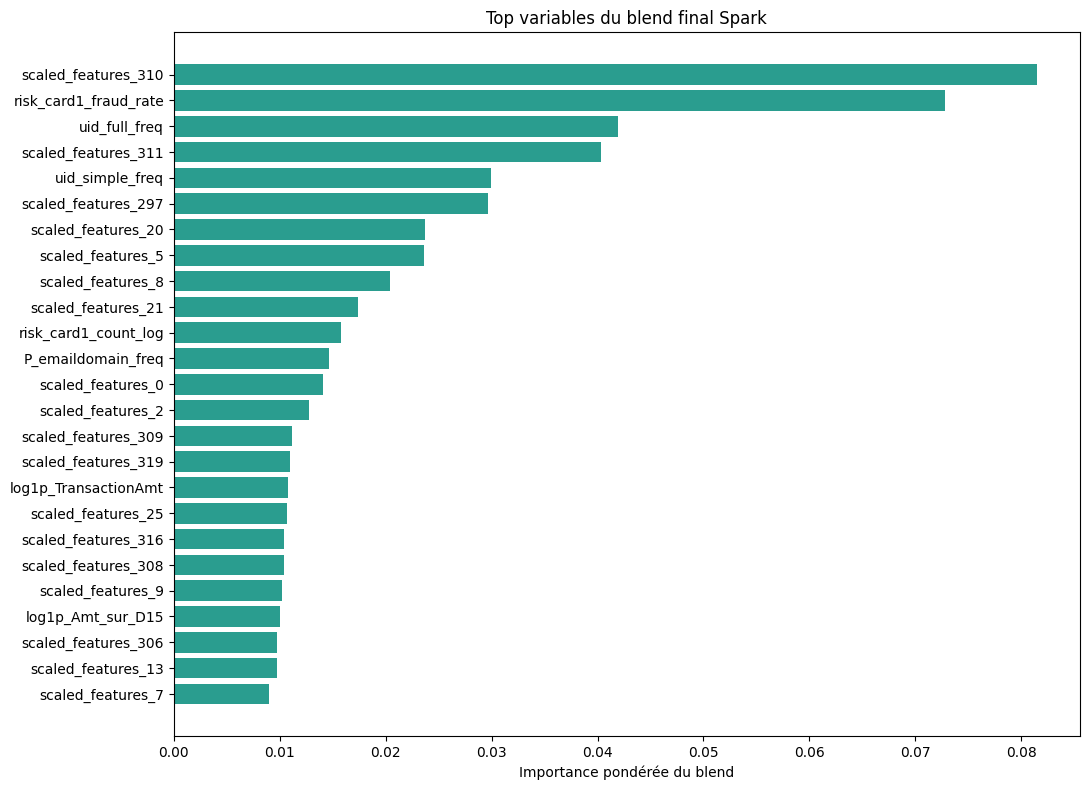

Graphique sauvegardé : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\plots\blend_feature_importance_bar.png


,feature_index,feature,importance
0,332,scaled_features_310,0.081471
1,453,risk_card1_fraud_rate,0.072763
2,495,uid_full_freq,0.041912
3,333,scaled_features_311,0.040356
4,494,uid_simple_freq,0.029945
5,319,scaled_features_297,0.029688
6,42,scaled_features_20,0.023743
7,27,scaled_features_5,0.023625
8,30,scaled_features_8,0.020406
9,43,scaled_features_21,0.017406


In [ ]:
feature_names = extract_feature_names_from_vector_metadata(test_df, features_col="features")

w_base = float(blend_selection["w_base"])
w_15 = float(blend_selection["w_x1.15"])
w_30 = float(blend_selection["w_x1.30"])

importance_arrays = {
    "base": base_model.featureImportances.toArray(),
    "x1.15": loaded_variants["gbt_classWeight_x1.15"].featureImportances.toArray(),
    "x1.30": loaded_variants["gbt_classWeight_x1.30"].featureImportances.toArray(),}
target_importance_len = max(len(feature_names), *(len(values) for values in importance_arrays.values()))


def align_importance(values, target_len, model_name):
    values = np.asarray(values, dtype=float)
    if len(values) < target_len:
        print(f"[Info] Importance {model_name}: padding {len(values)} -> {target_len}")
        return np.pad(values, (0, target_len - len(values)), constant_values=0.0)
    if len(values) > target_len:
        print(f"[Info] Importance {model_name}: truncation {len(values)} -> {target_len}")
        return values[:target_len]
    return values

importance_base = align_importance(importance_arrays["base"], target_importance_len, "base")
importance_15 = align_importance(importance_arrays["x1.15"], target_importance_len, "x1.15")
importance_30 = align_importance(importance_arrays["x1.30"], target_importance_len, "x1.30")

if len(feature_names) < target_importance_len:
    feature_names = feature_names + [f"feature_{idx}" for idx in range(len(feature_names), target_importance_len)]
elif len(feature_names) > target_importance_len:
    feature_names = feature_names[:target_importance_len]

blend_importance = w_base * importance_base + w_15 * importance_15 + w_30 * importance_30

feature_importance_df = (
    pd.DataFrame({"feature_index": range(len(blend_importance)), "feature": feature_names, "importance": blend_importance})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True))
feature_importance_df.head(50).to_csv(METRICS_DIR / "blend_feature_importance_top50.csv", index=False)

print(
    "Longueurs importances :",
    {name: len(values) for name, values in importance_arrays.items()},
    "-> longueur alignée:",
    len(blend_importance),)

top_importance = feature_importance_df.head(25).iloc[::-1]
plt.figure(figsize=(11, 8))
plt.barh(top_importance["feature"], top_importance["importance"], color="#2A9D8F")
plt.xlabel("Importance pondérée du blend")
plt.title("Top variables du blend final Spark")
plt.tight_layout()
importance_plot_path = PLOTS_DIR / "blend_feature_importance_bar.png"
plt.savefig(importance_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Graphique sauvegardé : {importance_plot_path}")
display(feature_importance_df.head(25))


## 5. SHAP sur un échantillon du test

Comme le modèle final est un blend Spark, SHAP est calculé avec `KernelExplainer` sur un petit échantillon du test.

L'objectif est d'obtenir une explication lisible sans relancer un calcul trop lourd sur les `506 691` lignes. Le bar plot SHAP classe les variables par impact moyen absolu ; le beeswarm montre le sens de l'impact sur les transactions expliquées.

[Spark->Pandas] échantillon SHAP: shape=(55, 1)
[Spark->Pandas] batch SHAP scoring: shape=(15, 3)


  0%|          | 0/40 [00:00<?, ?it/s]

[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1200, 3)
[Spark->Pandas] batch SHAP scoring: shape=(1, 3)
[Spark->Pandas] batch SHAP scoring: shape=

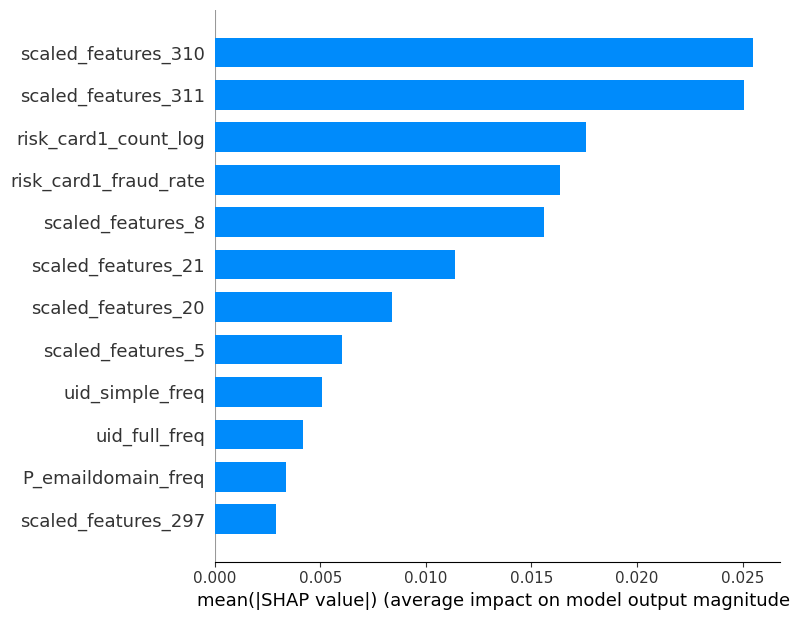

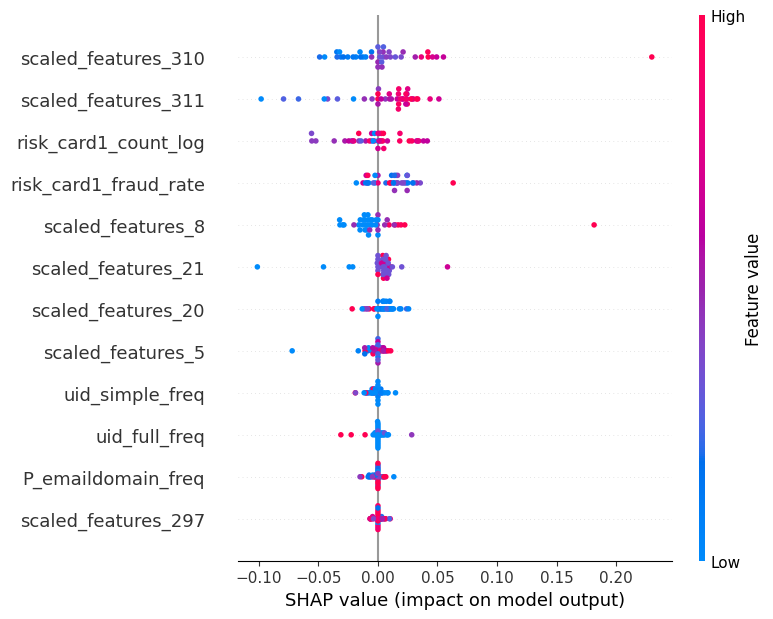

SHAP bar sauvegardé : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\plots\shap_blend_bar.png
SHAP beeswarm sauvegardé : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\plots\shap_blend_beeswarm.png


,feature,mean_abs_shap
0,scaled_features_310,0.025499
3,scaled_features_311,0.025081
10,risk_card1_count_log,0.017572
1,risk_card1_fraud_rate,0.016355
8,scaled_features_8,0.015601
9,scaled_features_21,0.011369
6,scaled_features_20,0.008409
7,scaled_features_5,0.006032
4,uid_simple_freq,0.005090
2,uid_full_freq,0.004200


In [ ]:
if RUN_SHAP_KERNEL:
    import shap

    shap_total_rows = SHAP_BACKGROUND_ROWS + SHAP_EXPLAIN_ROWS
    shap_sample_spark = (
        test_df
        .orderBy(rand(SEED))
        .select(vector_to_array("features").alias("features_array"))
        .limit(shap_total_rows))
    shap_sample_pdf = safe_to_pandas(shap_sample_spark, context="échantillon SHAP")
    X_full = np.vstack(shap_sample_pdf["features_array"].apply(lambda values: np.asarray(values, dtype=float)).to_numpy())

    background_full = X_full[:SHAP_BACKGROUND_ROWS]
    explain_full = X_full[SHAP_BACKGROUND_ROWS:]

    top_feature_rows = feature_importance_df.head(SHAP_TOP_N).copy()
    top_indices = top_feature_rows["feature_index"].astype(int).to_numpy()
    top_names = top_feature_rows["feature"].tolist()
    baseline_full = background_full.mean(axis=0)

    vector_schema = StructType([StructField("features", VectorUDT(), False)])

    def predict_blend_from_full_matrix(matrix):
        rows = [(Vectors.dense(row.tolist()),) for row in np.asarray(matrix, dtype=float)]
        matrix_df = spark.createDataFrame(rows, schema=vector_schema)
        scores_spark = score_three_way_blend_spark(matrix_df, base_model, loaded_variants)
        scores_pdf = safe_to_pandas(scores_spark, context="batch SHAP scoring")
        scored_pdf = apply_three_way_blend_config(scores_pdf, blend_selection, calibrators=calibrators)
        return scored_pdf["fraud_probability"].to_numpy()

    def predict_from_top_features(top_matrix):
        top_matrix = np.asarray(top_matrix, dtype=float)
        full_matrix = np.tile(baseline_full, (top_matrix.shape[0], 1))
        full_matrix[:, top_indices] = top_matrix
        return predict_blend_from_full_matrix(full_matrix)

    background_top = background_full[:, top_indices]
    explain_top = explain_full[:, top_indices]

    explainer = shap.KernelExplainer(predict_from_top_features, background_top)
    shap_values = explainer.shap_values(explain_top, nsamples=SHAP_NSAMPLES)
    shap_values = np.asarray(shap_values)

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_values, explain_top, feature_names=top_names, plot_type="bar", show=False, max_display=SHAP_TOP_N)
    shap_bar_path = PLOTS_DIR / "shap_blend_bar.png"
    plt.tight_layout()
    plt.savefig(shap_bar_path, dpi=150, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_values, explain_top, feature_names=top_names, show=False, max_display=SHAP_TOP_N)
    shap_beeswarm_path = PLOTS_DIR / "shap_blend_beeswarm.png"
    plt.tight_layout()
    plt.savefig(shap_beeswarm_path, dpi=150, bbox_inches="tight")
    plt.show()

    shap_summary = pd.DataFrame(
        {
            "feature": top_names,
            "mean_abs_shap": np.abs(shap_values).mean(axis=0),
        }
    ).sort_values("mean_abs_shap", ascending=False)
    shap_summary.to_csv(METRICS_DIR / "shap_blend_summary.csv", index=False)

    print(f"SHAP bar sauvegardé : {shap_bar_path}")
    print(f"SHAP beeswarm sauvegardé : {shap_beeswarm_path}")
    display(shap_summary)
else:
    print("RUN_SHAP_KERNEL=False : SHAP non exécuté. Mets RUN_SHAP_KERNEL=True pour générer les deux graphes SHAP.")


### Lecture SHAP

- Le top SHAP moyen retrouve `scaled_features_310`, `scaled_features_311`, `risk_card1_count_log`, `risk_card1_fraud_rate` et plusieurs `scaled_features_*`.
- La cohérence avec l'importance globale renforce l'idée que le blend s'appuie surtout sur des signaux anonymisés forts, complétés par le risque `card1` et les fréquences `uid`.
- Le bar plot classe les variables par impact moyen absolu sur la probabilité prédite.
- Le beeswarm montre le sens de l'effet : points à droite = contribution vers fraude, points à gauche = contribution vers non-fraude.


## 6. Synthèse des sorties

Ce notebook valide la logique batch d'inférence : préparation du test, alignement du vecteur `features`, chargement des trois modèles Spark, application du blend calibré et export des prédictions.

À retenir :
- le test complet contient `506 691` transactions scorées ;
- le vecteur final est bien aligné en `725` dimensions ;
- le blend final applique la famille `cal` avec le seuil `0.224` ;
- `23 943` transactions sont prédites frauduleuses, soit `4.73 %` du test ;
- les graphiques `feature importance`, `SHAP bar` et `SHAP beeswarm` servent à expliquer les signaux dominants.

Ces prédictions sont des scores de risque, pas des métriques de performance, car `isFraud` n'est pas disponible sur le test.

Pour la suite applicative, cette logique peut être réutilisée dans `main.py` ou dans une API FastAPI afin de recevoir quelques transactions et renvoyer `fraud_probability` + `fraud_pred`.


In [12]:
print("Notebook 08 terminé.")
print(f"Prédictions : {PREDICTIONS_DIR / 'test_predictions_blend.csv'}")
print(f"Importance globale : {PLOTS_DIR / 'blend_feature_importance_bar.png'}")
print(f"SHAP bar : {PLOTS_DIR / 'shap_blend_bar.png'}")
print(f"SHAP beeswarm : {PLOTS_DIR / 'shap_blend_beeswarm.png'}")


Notebook 08 terminé.
Prédictions : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\predictions\test_predictions_blend.csv
Importance globale : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\plots\blend_feature_importance_bar.png
SHAP bar : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\plots\shap_blend_bar.png
SHAP beeswarm : C:\Users\El-fahad COMBO\Desktop\Fraud_Detection_IEEE\artifacts\08_test_preparation\plots\shap_blend_beeswarm.png


In [13]:
spark.stop()
